## <center> **Logistic regression: Practice**

### Контекст задачи:

Некоторый банк обратился за помощью: он хочет разработать кампанию лояльности по удержанию клиентов. Для этого ему необходимо прогнозировать вероятности оттока клиентов и определять, уйдёт ли клиент в ближайшее время.

### Задача:
Построить классификатор, который позволит своевременно определять уходящих клиентов банка, оценить качество построенных моделей и проинтерпретировать результаты.

Основные требования к модели:
* Высокая точность определения целевого класса;
* Максимально возможный охват целевой группы;

In [1]:
# data manipulation
import pandas as pd
import numpy as np
# visualization
import matplotlib.pyplot as plt
import seaborn as sns
# machine learning
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn import metrics

In [2]:
# read data
churn_original = pd.read_csv('data/churn.csv')
churn = churn_original.copy()
display(churn.head())
churn = churn[churn['Geography'] == 'Germany']  # filter for Germany only
# drop useless features
churn = churn.drop(['Geography', 'RowNumber', 'CustomerId', 'Surname'], axis=1)
display(churn.head())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
7,376,Female,29,4,115046.74,4,1,0,119346.88,1
15,616,Male,45,3,143129.41,2,0,1,64327.26,0
16,653,Male,58,1,132602.88,1,1,0,5097.67,1
26,756,Male,36,2,136815.64,1,1,1,170041.95,0
28,574,Female,43,3,141349.43,1,1,1,100187.43,0


In [3]:
# check data types and missing values and duplicates
churn.info()
display('missing values', churn.isnull().sum())
display('duplicates', churn[churn.duplicated()].sum())

<class 'pandas.DataFrame'>
Index: 2509 entries, 7 to 9998
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      2509 non-null   int64  
 1   Gender           2509 non-null   str    
 2   Age              2509 non-null   int64  
 3   Tenure           2509 non-null   int64  
 4   Balance          2509 non-null   float64
 5   NumOfProducts    2509 non-null   int64  
 6   HasCrCard        2509 non-null   int64  
 7   IsActiveMember   2509 non-null   int64  
 8   EstimatedSalary  2509 non-null   float64
 9   Exited           2509 non-null   int64  
dtypes: float64(2), int64(7), str(1)
memory usage: 215.6 KB


'missing values'

CreditScore        0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

'duplicates'

CreditScore        0.0
Gender             0.0
Age                0.0
Tenure             0.0
Balance            0.0
NumOfProducts      0.0
HasCrCard          0.0
IsActiveMember     0.0
EstimatedSalary    0.0
Exited             0.0
dtype: float64

## <center>**Логистическая регрессия**

#### **5.1 Создание признаков:**
* BalanceSalaryRatio;
* TenureByAge;
* CreditScoreGivenAge;

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceSalaryRatio,TenureByAge,CreditScoreGivenAge,Male
count,2509.000000,2509.000000,2509.000000,2509.000000,2509.000000,2509.00000,2509.000000,2509.000000,2509.000000,2509.000000,2509.000000,2509.000000,2509.000000
mean,651.453567,39.771622,5.009964,119730.116134,1.519729,0.71383,0.497409,101113.435102,0.324432,9.024870,0.134356,17.526465,0.524512
std,98.168937,10.519143,2.935154,27022.006157,0.619420,0.45206,0.500093,58263.011501,0.468256,214.286102,0.087680,5.349574,0.499498
min,350.000000,18.000000,0.000000,27288.430000,1.000000,0.00000,0.000000,11.580000,0.000000,0.190000,0.000000,6.110000,0.000000
25%,584.000000,32.000000,2.000000,102800.720000,1.000000,0.00000,0.000000,51016.020000,0.000000,0.780000,0.060000,13.690000,0.000000
50%,651.000000,38.000000,5.000000,119703.100000,1.000000,1.00000,0.000000,102397.220000,0.000000,1.200000,0.120000,16.860000,1.000000
75%,722.000000,45.000000,8.000000,137560.380000,2.000000,1.00000,1.000000,151083.800000,1.000000,2.400000,0.200000,20.850000,1.000000
max,850.000000,84.000000,10.000000,214346.960000,4.000000,1.00000,1.000000,199970.740000,1.000000,10614.660000,0.500000,46.390000,1.000000


Exited
0    0.68
1    0.32
Name: proportion, dtype: float64

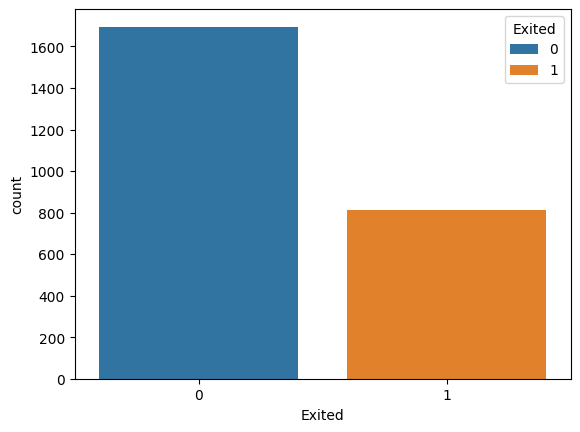

In [4]:
# create new features
churn['BalanceSalaryRatio'] = (churn['Balance'] / churn['EstimatedSalary']).round(2)
churn['TenureByAge'] = (churn['Tenure'] / churn['Age']).round(2)
churn['CreditScoreGivenAge'] = (churn['CreditScore'] / churn['Age']).round(2)
# code gender as binary variable
churn['Male'] = churn['Gender'].apply(lambda x: 1 if x == 'Male' else 0)
churn.drop(['Gender'], axis=1, inplace=True)
# main statistics of the data
display(churn.describe())
# balance of Exited 
plot = sns.countplot(x='Exited', data=churn, hue='Exited')
churn['Exited'].value_counts(normalize=True).round(2)

#### **Делим данные на тренировочную и тестовую выборки** 

In [5]:
# split the data
X = churn.drop(['Exited'], axis=1)
y = churn['Exited']
# split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0, stratify=y)
print('Train set:', X_train.shape)   
print('Test set:', X_test.shape)
# check the balance 
print('Train :')
display(y_train.value_counts(normalize=True).round(3))
print('Test :')
display(y_test.value_counts(normalize=True).round(3))

Train set: (1881, 12)
Test set: (628, 12)
Train :


Exited
0    0.676
1    0.324
Name: proportion, dtype: float64

Test :


Exited
0    0.675
1    0.325
Name: proportion, dtype: float64

#### **5.2 Создание и обучение MinMaxScaler()**


In [6]:
# scale the data
scaler = preprocessing.MinMaxScaler()
# train scaler on train data
scaler.fit(X_train)
# transform train and test data
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### **5.3 Обоснование выбора метрики *F1-score***
По условию задачи необходимо обеспечить высокую точность определения целевого класса, одновременно охватывая как можно большее число клиентов. Для решения данной задачи целесообразно использовать F1-меру, представляющую собой гармоническое среднее значений Precision и Recall. Однако окончательное решение стоит принимать по совокупности метрик. Дело в том, что F1-score является оценкой сбалансированности Precision и Recall, а не оценкой качества модели в целом.

* Precision — точность определения целевого класса.
* Recall — охват объектов, действительно принадлежащих к целевому классу.

**F1-score = (2 × Precision × Recall) / (Precision + Recall)**

#### **5.4 Обучение модели линейной регрессии и интерпретация результатов**

In [7]:
# train the model
log_reg = linear_model.LogisticRegression(solver='sag', random_state=42, max_iter=10000)
log_reg.fit(X_train_scaled, y_train)
# make predictions
y_train_pred = log_reg.predict(X_train_scaled)
y_test_pred = log_reg.predict(X_test_scaled)
# metrics
print('Train set:')
print(metrics.classification_report(y_train, y_train_pred))
print('Test set:')
print(metrics.classification_report(y_test, y_test_pred))


Train set:
              precision    recall  f1-score   support

           0       0.76      0.89      0.82      1271
           1       0.63      0.40      0.49       610

    accuracy                           0.73      1881
   macro avg       0.69      0.64      0.65      1881
weighted avg       0.72      0.73      0.71      1881

Test set:
              precision    recall  f1-score   support

           0       0.75      0.89      0.82       424
           1       0.63      0.38      0.47       204

    accuracy                           0.73       628
   macro avg       0.69      0.64      0.64       628
weighted avg       0.71      0.73      0.70       628



**Интерпретация результатов:**

F1-мера на тестовой выборке составляет 0.47. Это является довольно посредственным результатом.

* Точность (precision) - 0.63, можно интерпретировать как: 63% клиентов действительно принадлежат к нелояльной группе.
* Охват (recall) - 0.38, значит, что из всех клиентов, принадлежащих к нелояльной группе, модель смогла определить только 38%.

Даже при относительно высокой точности модель не способна охватить большую часть клиентов. Данная модель не справляется с поставленной задачей, так же ее можно считать недообученой. 

#### **5.5 Полиномиальные признаки и интерпретация результатов** 

In [8]:
# Polynomial features
poly = preprocessing.PolynomialFeatures(degree=3, include_bias=False)
poly.fit(X_train_scaled)
# 
X_train_scaled_poly = poly.transform(X_train_scaled)
X_test_scaled_poly = poly.transform(X_test_scaled)
# train the model
log_reg.fit(X_train_scaled_poly, y_train)
# prediction
y_train_pred_poly = log_reg.predict(X_train_scaled_poly)
y_test_pred_poly = log_reg.predict(X_test_scaled_poly)
# metrics
print('Train set:')
print(metrics.classification_report(y_train, y_train_pred_poly))
print('Test set:')
print(metrics.classification_report(y_test, y_test_pred_poly))

Train set:
              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1271
           1       0.78      0.56      0.66       610

    accuracy                           0.81      1881
   macro avg       0.80      0.74      0.76      1881
weighted avg       0.80      0.81      0.80      1881

Test set:
              precision    recall  f1-score   support

           0       0.81      0.90      0.85       424
           1       0.73      0.56      0.64       204

    accuracy                           0.79       628
   macro avg       0.77      0.73      0.74       628
weighted avg       0.78      0.79      0.78       628



In [9]:
print('Number of features before transformation', X_train_scaled.shape[1])
print('Number of features after transformation', X_train_scaled_poly.shape[1])


Number of features before transformation 12
Number of features after transformation 454


**Интерпретация результатов:**

Охват (Recall) на тестовой выборке составил 0.01, что свидетельствует о крайне низкой способности модели выявлять клиентов, относящихся к группе нелояльных. Вероятно, одной из причин стало значительное увеличение количества признаков: после полиномиального преобразования число признаков выросло с 12 до 454. В результате модели оказалось сложно подобрать оптимальные веса для такого количества переменных. Таким образом, добавление полиномиальных признаков не только не улучшило качество модели, но и привело к его ухудшению.

#### **5.6 Подбор оптимального порога классификации**

Model's metrics with threshold 0.30
              precision    recall  f1-score   support

           0       0.82      0.61      0.70       424
           1       0.47      0.73      0.57       204

    accuracy                           0.65       628
   macro avg       0.65      0.67      0.64       628
weighted avg       0.71      0.65      0.66       628

Model's metrics with threshold 0.40
              precision    recall  f1-score   support

           0       0.79      0.78      0.78       424
           1       0.55      0.56      0.55       204

    accuracy                           0.71       628
   macro avg       0.67      0.67      0.67       628
weighted avg       0.71      0.71      0.71       628

Model's metrics with threshold 0.35
              precision    recall  f1-score   support

           0       0.80      0.70      0.75       424
           1       0.51      0.65      0.57       204

    accuracy                           0.68       628
   macro avg       0

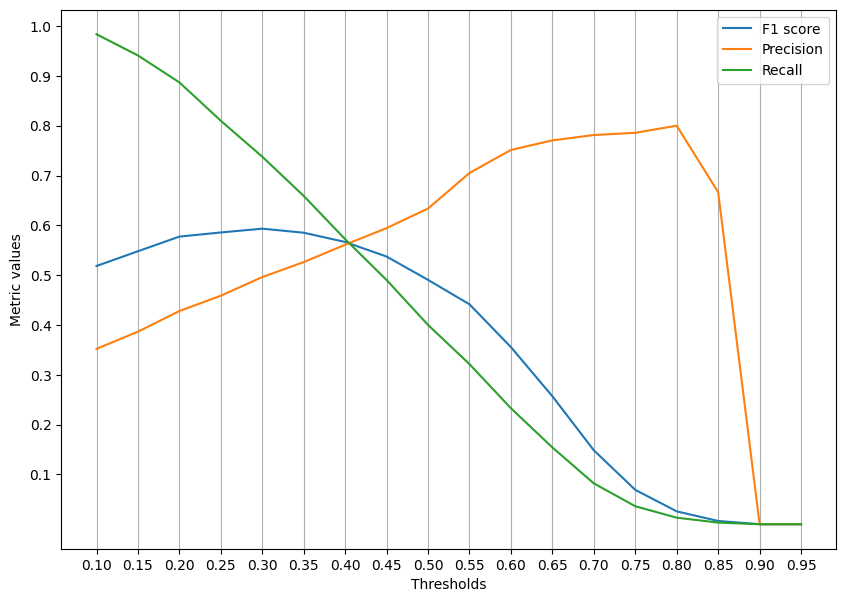

In [10]:
thresholds = np.arange(0.1, 1, 0.05)
# train the model
log_reg.fit(X_train_scaled, y_train)
# Probability estimation
y_train_proba = log_reg.predict_proba(X_train_scaled)[:, 1]
#
f1_score_lr = []
precision_lr = []
recall_lr = []
#
for threshold in thresholds:
    y_train_pred_lr = (y_train_proba > threshold).astype(int)
    f1_score_lr.append(metrics.f1_score(y_true=y_train, y_pred=y_train_pred_lr, zero_division=0))
    precision_lr.append(metrics.precision_score(y_true=y_train, y_pred=y_train_pred_lr, zero_division=0))
    recall_lr.append(metrics.recall_score(y_true=y_train, y_pred=y_train_pred_lr, zero_division=0))
# plot
fig = plt.figure(figsize=(10, 7))
plot = sns.lineplot(x=thresholds, y=f1_score_lr, label='F1 score')
plot = sns.lineplot(x=thresholds, y=precision_lr, label='Precision')
plot = sns.lineplot(x=thresholds, y=recall_lr, label='Recall')
plot.set_xticks(thresholds)
plot.set_yticks(np.arange(0.1, 1.1, 0.1))
plot.set_xlabel('Thresholds')
plot.set_ylabel('Metric values')
plot.grid(axis='x')
# apply optimal threshold to test set
y_test_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
# thresholds
y_pred_lr_03 = (y_test_proba_lr > 0.3).astype(int)
y_pred_lr_04 = (y_test_proba_lr > 0.4).astype(int)
y_pred_lr_35 = (y_test_proba_lr > 0.35).astype(int)
# metrics
print("Model's metrics with threshold 0.30")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_lr_03))
print("Model's metrics with threshold 0.40")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_lr_04))
print("Model's metrics with threshold 0.35")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_lr_35))

**Интерпретация результатов:**

График зависимости метрик модели от порога классификации демонстрирует, что для поставленной задачи опираться слепо на F1-меру поспешно. Максимум F1-меры - 0.57 достигается при значении порога классификации 0.30, однако другие метрики выглядят неудовлетворительно: 47% точности (precision) говорит о том, что более чем в половине случаев ресурсы компании будут расходоваться впустую. 73% охвата (recall) нелояльной группы модель смогла определить, это высокий показатель, но в совокупности с низкой точностью данная модель с порогом классификации 0.30 не подходит для решения поставленной задачи.

График показывает, что оптимальный порог классификации можно принять 0.40. При этом F1-мера - 0.55, ниже предыдущего значения 0.57. В то же время другие метрики: точность (precision) - 55% и охват (recall) - 56% свидетельствуют о том, что в большинстве случаев модель не ошибается в определении целевого класса и охватывает более половины клиентов. Данные результаты довольно посредственны, однако порог классификации 0.40 лучше решает основную задачу.

Порог классификации 0.35 является возможным вариантом в данном случае. При таком значении F1-мера составляет 0.57, это максимальное значение из возможных. При этом точность (precision) 51%, что ниже предыдущего показателя. Одновременно с этим модель охватывает (recall) 65% целевой группы. Потеря 4% точности в обмен на дополнительные 10% охвата является одним из возможных компромиссов для решения задачи.

## <center>**Деревья решений и Случайный лес**

In [11]:
from sklearn import tree
from sklearn import ensemble

In [12]:
X = churn.drop(['Exited'], axis=1) # features
y = churn['Exited'] # true 
# split the data 
x_train, x_test, y_train, y_test = train_test_split(X,y, random_state=42, stratify=y)

#### **8.1 Дерево решений с неограниченной глубиной**

In [13]:
# Decision tree model
dt_model = tree.DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_model.fit(x_train, y_train)
dt_pred_train = dt_model.predict(x_train)
dt_pred_test = dt_model.predict(x_test)
# metrics 
print('Train set:')
print(metrics.classification_report(y_true=y_train, y_pred=dt_pred_train))
print('Test set:')
print(metrics.classification_report(y_true=y_test, y_pred=dt_pred_test))

Train set:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1271
           1       1.00      1.00      1.00       610

    accuracy                           1.00      1881
   macro avg       1.00      1.00      1.00      1881
weighted avg       1.00      1.00      1.00      1881

Test set:
              precision    recall  f1-score   support

           0       0.80      0.80      0.80       424
           1       0.58      0.57      0.58       204

    accuracy                           0.73       628
   macro avg       0.69      0.69      0.69       628
weighted avg       0.73      0.73      0.73       628



**Интерпретация результатов:**

Метрики указывают, что модель идеально справляется на тренировочной выборке: охват (recall) целевой группы составляет 100%, а точность (precision) также достигает 100%. Модель можно считать переобученной.

На тестовой выборке значения метрик существенно ниже чем на тернировочной, что подтверждает наличие переобучения. В связи с этим детальный анализ результатов данной модели не имеет практического смысла.

#### **8.2 Дерево решений с ограничением глубины и размера листа**

In [14]:
# decision tree model
dt_model = tree.DecisionTreeClassifier(
    criterion='entropy',
    random_state=42,
    max_depth=8,
    min_samples_leaf=10
)
dt_model.fit(x_train, y_train)
dt_pred_train = dt_model.predict(x_train)
dt_pred_test = dt_model.predict(x_test)
# metrics
print('Train set:')
print(metrics.classification_report(y_true=y_train, y_pred=dt_pred_train))
print('Test set:')
print(metrics.classification_report(y_true=y_test, y_pred=dt_pred_test))

Train set:
              precision    recall  f1-score   support

           0       0.85      0.93      0.88      1271
           1       0.81      0.65      0.72       610

    accuracy                           0.84      1881
   macro avg       0.83      0.79      0.80      1881
weighted avg       0.83      0.84      0.83      1881

Test set:
              precision    recall  f1-score   support

           0       0.80      0.87      0.84       424
           1       0.68      0.55      0.61       204

    accuracy                           0.77       628
   macro avg       0.74      0.71      0.72       628
weighted avg       0.76      0.77      0.76       628



**Интерпретация результатов:**

Метрики демонстрируют, что ограничение глубины дерева и размера листьев позволяет снизить переобучение модели. Модель показывает себя лучше на тренировочной выборке, однако не идеально: точность (precision) - 81%, охват (recall) - 65%, F1-мера (f1-score) - 0.72. Результаты тестовой выборки говорят, что модель определяет целевой класс достаточно точно: точность (precision) - 68%, при этом охват (recall) составляет всего 55%.

Модель хоть и обладает приемлемой точностью, но вместе с тем упускает значимую часть клиентов нелояльной группы.

#### **8.3 Случайный лес**

In [15]:
# Random forest model
rf_model = ensemble.RandomForestClassifier(
    n_estimators=500,
    criterion='entropy',
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)
rf_model.fit(x_train, y_train)
rf_pred_train = rf_model.predict(x_train)
rf_pred_test = rf_model.predict(x_test)
# metrics
print('Train set:')
print(metrics.classification_report(y_true=y_train, y_pred=rf_pred_train))
print("Test set:")
print(metrics.classification_report(y_true=y_test, y_pred=rf_pred_test))

Train set:
              precision    recall  f1-score   support

           0       0.85      0.94      0.89      1271
           1       0.85      0.65      0.74       610

    accuracy                           0.85      1881
   macro avg       0.85      0.80      0.81      1881
weighted avg       0.85      0.85      0.84      1881

Test set:
              precision    recall  f1-score   support

           0       0.80      0.92      0.85       424
           1       0.74      0.51      0.60       204

    accuracy                           0.78       628
   macro avg       0.77      0.71      0.73       628
weighted avg       0.78      0.78      0.77       628



**Интерпретация результатов:**

Данный тип моделей - Случайный лес показал прирост точности (precision) в определении целевого класса на тестовой выборке: 74% против 68% у дерева решений. Вместе с этим несколько пострадал охват (recall): 51% вместо 55% у предыдущей модели. F1-мера сопоставима у обеих моделей.

Выделить одну из моделей на данном этапе сложно, обе являются компромиссным решением задачи, но не оптимальным.

#### **8.4 Подбор оптимального порога классификации**

Model's metrics with threshold 0.30
              precision    recall  f1-score   support

           0       0.85      0.72      0.78       424
           1       0.56      0.73      0.63       204

    accuracy                           0.73       628
   macro avg       0.70      0.73      0.71       628
weighted avg       0.75      0.73      0.73       628

Model's metrics with threshold 0.35
              precision    recall  f1-score   support

           0       0.84      0.78      0.81       424
           1       0.60      0.69      0.64       204

    accuracy                           0.75       628
   macro avg       0.72      0.73      0.73       628
weighted avg       0.76      0.75      0.76       628

Model's metrics with threshold 0.40
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       424
           1       0.65      0.65      0.65       204

    accuracy                           0.77       628
   macro avg       0

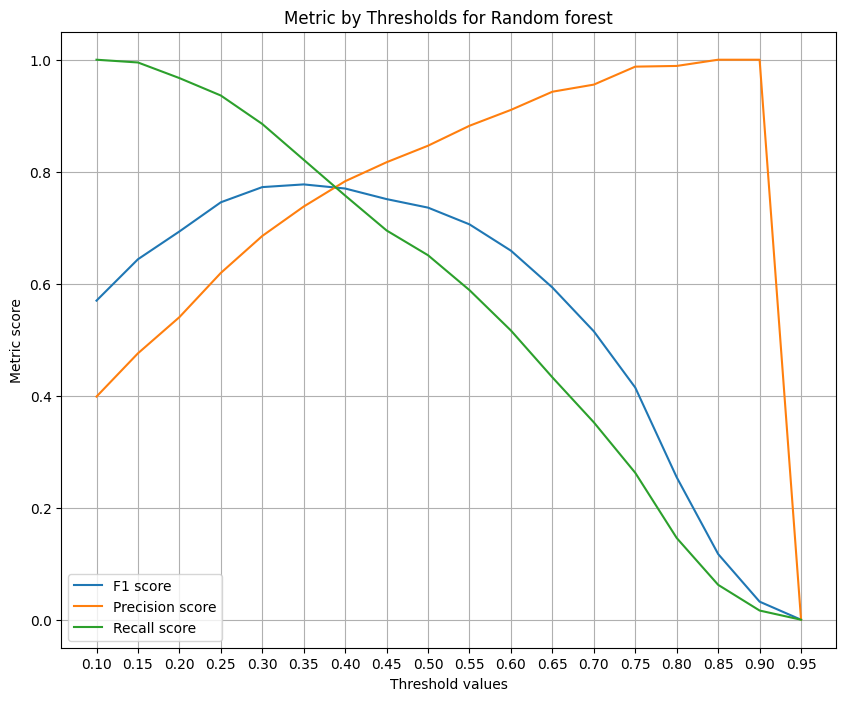

In [16]:
thresholds = np.array(np.arange(0.1, 1, 0.05))
# tuning parameters Randome forest
y_train_pred_proba_rf = rf_model.predict_proba(x_train)[:, 1]
f1_score_rf = []
precision_score_rf = []
recall_score_rf = []
# Randome forest thresholds
for threshold in thresholds:
    y_train_pred_rf = (y_train_pred_proba_rf > threshold).astype(int)
    f1_score_rf.append(metrics.f1_score(y_true=y_train, y_pred=y_train_pred_rf, zero_division=0))
    precision_score_rf.append(metrics.precision_score(y_true=y_train, y_pred=y_train_pred_rf, zero_division=0))
    recall_score_rf.append(metrics.recall_score(y_true=y_train, y_pred=y_train_pred_rf, zero_division=0))
# Randome forest plot
fig = plt.figure(figsize=(10, 8))
plot_rf = sns.lineplot(x=thresholds, y=f1_score_rf, label='F1 score')
plot_rf = sns.lineplot(x=thresholds, y=precision_score_rf, label='Precision score')
plot_rf = sns.lineplot(x=thresholds, y=recall_score_rf, label='Recall score', )
plot_rf.set_title('Metric by Thresholds for Random forest')
plot_rf.set_xlabel('Threshold values')
plot_rf.set_ylabel('Metric score')
plot_rf.set_xticks(thresholds)
plot_rf.grid()
plot_rf.legend()
# apply optimal threshold to test set 
y_test_proba_rf = rf_model.predict_proba(x_test)[:, 1]
# thresholds
y_pred_rf_03 = (y_test_proba_rf > 0.3).astype(int)
y_pred_rf_35 = (y_test_proba_rf > 0.35).astype(int)
y_pred_rf_40 = (y_test_proba_rf > 0.4).astype(int)
# metrics 
print("Model's metrics with threshold 0.30")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_rf_03))
print("Model's metrics with threshold 0.35")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_rf_35))
print("Model's metrics with threshold 0.40")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_rf_40))

**Интерпретация результатов:**

График демонстрирует три порога классификации, при которых наблюдается наивысший показатель целевой метрики:

* F1-мера - 0.63 при пороге классификации 0.30. Данные настройки подходят, если важнее обеспечить широкий охват (recall) - 73% при относительно приемлемой точности (precision) - 56%. Данное решение не подходит для решения поставленной задачи, вместе с тем не является провальным.

Для достижения поставленной цели наиболее привлекательными вариантами порога классификации являются 0.35 и 0.40. Оба варианта обеспечивают высокую точность и достаточно широкий охват.

* Порог классификации 0.35 позволяет достигнуть точности прогноза (precision) 60% и охвата (recall) 69%, при этом целевая метрика составляет 0.64. Данная модель способна решить поставленную задачу с некоторым акцентом на охват (recall).

* Оптимальным решением можно считать значение порога принятия решения 0.40, при котором F1-мера составляет 0.65, а точность (precision) и охват (recall) составляют 65%. Данные параметры обеспечивают баланс между метриками, что отлично подходит для решения задачи.



Model's metrics with threshold 0.25
              precision    recall  f1-score   support

           0       0.85      0.71      0.77       424
           1       0.55      0.73      0.63       204

    accuracy                           0.72       628
   macro avg       0.70      0.72      0.70       628
weighted avg       0.75      0.72      0.73       628

Model's metrics with threshold 0.30
              precision    recall  f1-score   support

           0       0.84      0.73      0.78       424
           1       0.56      0.71      0.63       204

    accuracy                           0.73       628
   macro avg       0.70      0.72      0.71       628
weighted avg       0.75      0.73      0.73       628

Model's metrics with threshold 0.35
              precision    recall  f1-score   support

           0       0.83      0.78      0.80       424
           1       0.59      0.68      0.63       204

    accuracy                           0.74       628
   macro avg       0

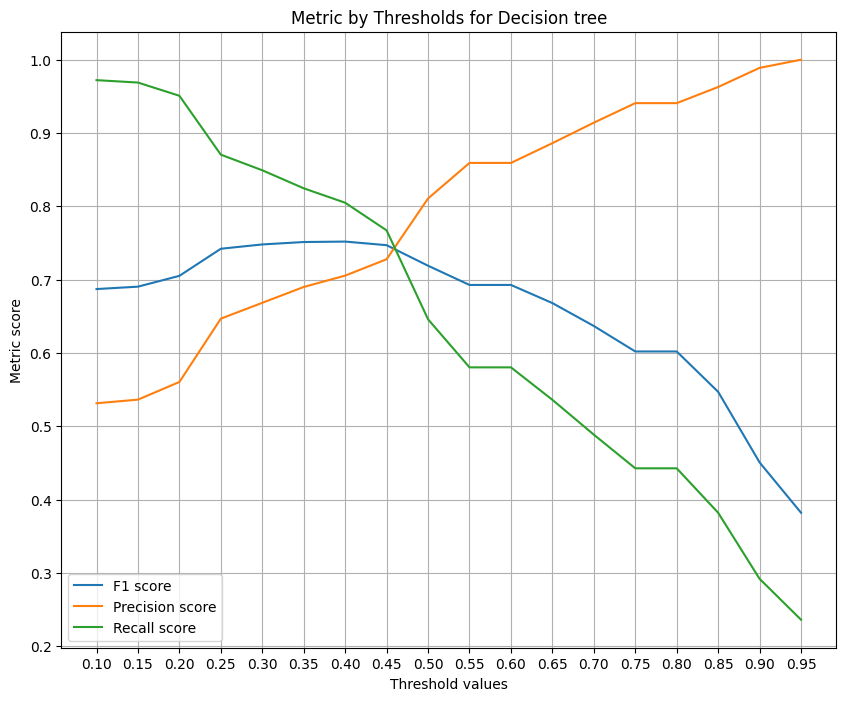

In [17]:
# tuning parameters decision tree
y_train_pred_proba_dt = dt_model.predict_proba(x_train)[:, 1]
f1_score_dt = []
precision_score_dt = []
recall_score_dt = []
# Decision tree thresholds
for threshold in thresholds:
    y_train_pred_dt = (y_train_pred_proba_dt > threshold).astype(int)
    f1_score_dt.append(metrics.f1_score(y_true=y_train, y_pred=y_train_pred_dt, zero_division=0))
    precision_score_dt.append(metrics.precision_score(y_true=y_train, y_pred=y_train_pred_dt, zero_division=0))
    recall_score_dt.append(metrics.recall_score(y_true=y_train, y_pred=y_train_pred_dt, zero_division=0))
# Decision tree plot
fig = plt.figure(figsize=(10, 8))
plot_dt = sns.lineplot(x=thresholds, y=f1_score_dt, label='F1 score')
plot_dt = sns.lineplot(x=thresholds, y=precision_score_dt, label='Precision score')
plot_dt = sns.lineplot(x=thresholds, y=recall_score_dt, label='Recall score')
plot_dt.set_title('Metric by Thresholds for Decision tree')
plot_dt.set_xlabel('Threshold values')
plot_dt.set_ylabel('Metric score')
plot_dt.set_xticks(thresholds)
plot_dt.grid()
plot_dt.legend()
# apply optimal threshold to test set 
y_test_proba_dt = dt_model.predict_proba(x_test)[:, 1]
# tresholds
y_pred_dt_25 = (y_test_proba_dt > 0.25).astype(int)
y_pred_dt_30 = (y_test_proba_dt > 0.30).astype(int)
y_pred_dt_35 = (y_test_proba_dt > 0.35).astype(int)
y_pred_dt_40 = (y_test_proba_dt > 0.40).astype(int)
y_pred_dt_45 = (y_test_proba_dt > 0.40).astype(int)
# metrics
print("Model's metrics with threshold 0.25")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_dt_25))
print("Model's metrics with threshold 0.30")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_dt_30))
print("Model's metrics with threshold 0.35")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_dt_35))
print("Model's metrics with threshold 0.40")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_dt_40))
print("Model's metrics with threshold 0.45")
print(metrics.classification_report(y_true=y_test, y_pred=y_pred_dt_45))

**Интерпретация результатов:**

На графике видно широкое плато целевой метрики, начиная со значения порога классификации 0.25 и заканчивая значением 0.45 включительно. При этих настройках классификации F1-мера составляет 0.63. При значении порога классификации:

* 0.25 - 0.30 наблюдаются соразмерные метрики точности (precision) 55% и охвата (recall) 73% в первом случае и 56% и 71% во втором. Данная модель с такими настройками не подходит для решения данной задачи, так как имеет явный перекос в сторону метрики recall.

* 0.40 - 0.45 остальные метрики одинаковы в обоих случаях: точность (precision) 59% и охват (recall) 66%. Эти настройки обеспечивают более сбалансированное соотношение метрик. Модель при этих параметрах демонстрирует высокую точность (precision) и широкий охват (recall). Однако, при шаге изменения порога 0.05 изменения метрик не наблюдается, поэтому нельзя сделать вывод о преимуществе одной настройки над другой.

Отдельно стоит отметить порог классификации 0.35. При этом значении метрики точности (precision) и охвата (recall) составляют 59% и 68%. Данные настройки обеспечивают наивысшие показатели метрик, это значит, что данная модель с такими настройками может оптимально решать поставленную задачу.

**Вывод:**

Опираясь на все вышесказанное, можно сделать вывод, что по совокупности метрик модель «Случайный лес» при пороге классификации 0.40 оптимально решает поставленную задачу. Метрики модели составляют:

* Точность (precision) - 65%;
* Охват (recall) - 65%;
* Целевая метрика (f1-score) - 0.65.

 
```python
rf_model = ensemble.RandomForestClassifier(
    n_estimators=500,
    criterion='entropy',
    max_depth=8,
    min_samples_leaf=10,
    random_state=42
)
```

#### **8.5 Определение вероятности оттока клиента банка** 

In [18]:
# dataframe
client = pd.DataFrame({
    'CreditScore': [601.0],
    'Gender': ['Male'],
    'Age': [42.0],
    'Tenure': [1.0],
    'Balance': [98495.72],
    'NumOfProducts': [1.0],
    'HasCrCard': [1.0],
    'IsActiveMember': [0.0],
    'EstimatedSalary': [40014.76]
})
# features
client['BalanceSalaryRatio'] = (client['Balance'] / client['EstimatedSalary']).round(2)
client['TenureByAge'] = (client['Tenure'] / client['Age']).round(2)
client['CreditScoreGivenAge'] = (client['CreditScore'] / client['Age']).round(2)
client['Male'] = client['Gender'].apply(lambda x: 1 if x == 'Male' else 0)
client.drop(['Gender'], axis=1, inplace=True)
# prediction
y_proba_client = rf_model.predict_proba(client)
print('Вероятность ухода клиента:',f'{y_proba_client[0, 1]:.2%}')

Вероятность ухода клиента: 59.17%
